In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

clean_matches = pd.read_csv("../data/processed/clean_matches.csv", parse_dates=["utcDate"])

In [2]:
home_goals = clean_matches.groupby("home_team_name")["home_goals"].sum()
away_goals = clean_matches.groupby("away_team_name")["away_goals"].sum()
total_goals = (home_goals.add(away_goals, fill_value=0)).sort_values(ascending=False)

In [3]:
home_conceded = clean_matches.groupby("home_team_name")["away_goals"].sum()
away_conceded = clean_matches.groupby("away_team_name")["home_goals"].sum()
total_conceded = (home_conceded.add(away_conceded, fill_value=0)).sort_values()

In [4]:
clean_matches["winner"].value_counts(normalize=True) * 100

winner
HOME_TEAM    42.631579
AWAY_TEAM    30.000000
DRAW         27.368421
Name: proportion, dtype: float64

In [5]:
clean_matches["home_goals"].mean()
clean_matches["away_goals"].mean()

np.float64(1.2236842105263157)

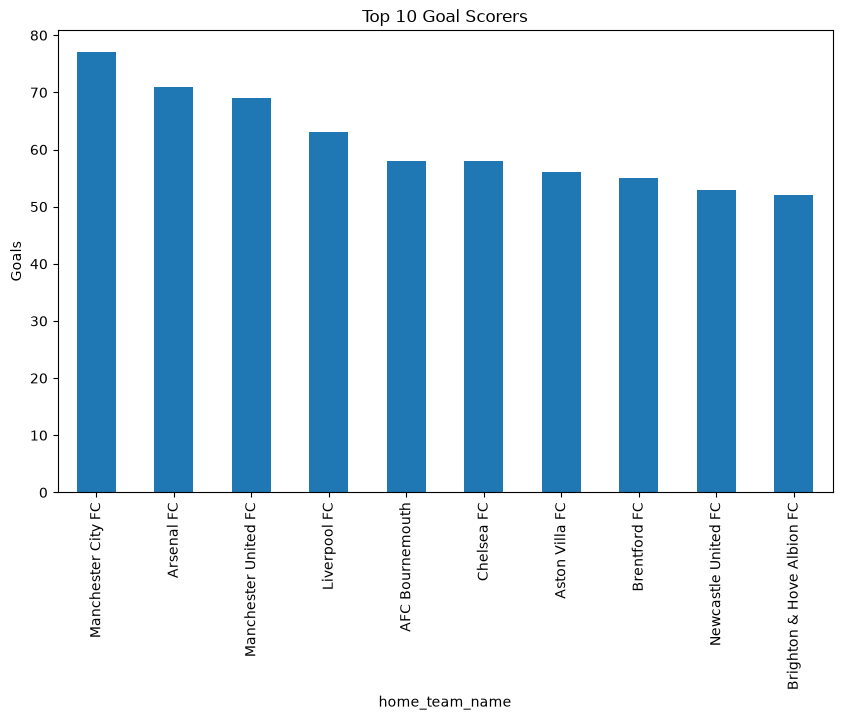

In [6]:
plt.figure(figsize=(10, 6))
total_goals.head(10).plot(kind="bar")
plt.title("Top 10 Goal Scorers")
plt.ylabel("Goals")
plt.show()

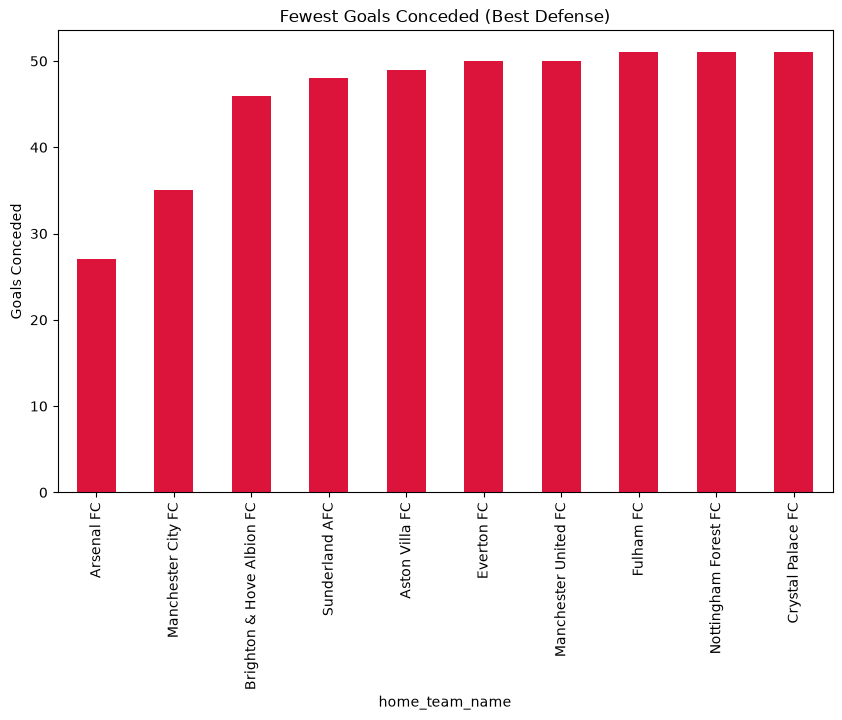

In [7]:
plt.figure(figsize=(10, 6))
total_conceded.head(10).plot(kind="bar", color="crimson")
plt.title("Fewest Goals Conceded (Best Defense)")
plt.ylabel("Goals Conceded")
plt.show()

In [8]:
clean_matches["winner"].value_counts(normalize=True) * 100

winner
HOME_TEAM    42.631579
AWAY_TEAM    30.000000
DRAW         27.368421
Name: proportion, dtype: float64

In [9]:
print("Avg home goals:", clean_matches["home_goals"].mean())
print("Avg away goals:", clean_matches["away_goals"].mean())

Avg home goals: 1.5263157894736843
Avg away goals: 1.2236842105263157


In [10]:
clean_matches["month"] = clean_matches["utcDate"].dt.month_name()
clean_matches["total_match_goals"] = clean_matches["home_goals"] + clean_matches["away_goals"]

In [11]:
goals_by_month = clean_matches.groupby("month")["total_match_goals"].sum()

season_month_order = ["August", "September", "October", "November", "December",
                       "January", "February", "March", "April", "May"]

goals_by_month = goals_by_month.reindex(season_month_order)
goals_by_month

month
August        78
September     79
October       84
November     119
December     164
January      130
February     117
March         74
April         82
May          118
Name: total_match_goals, dtype: int64

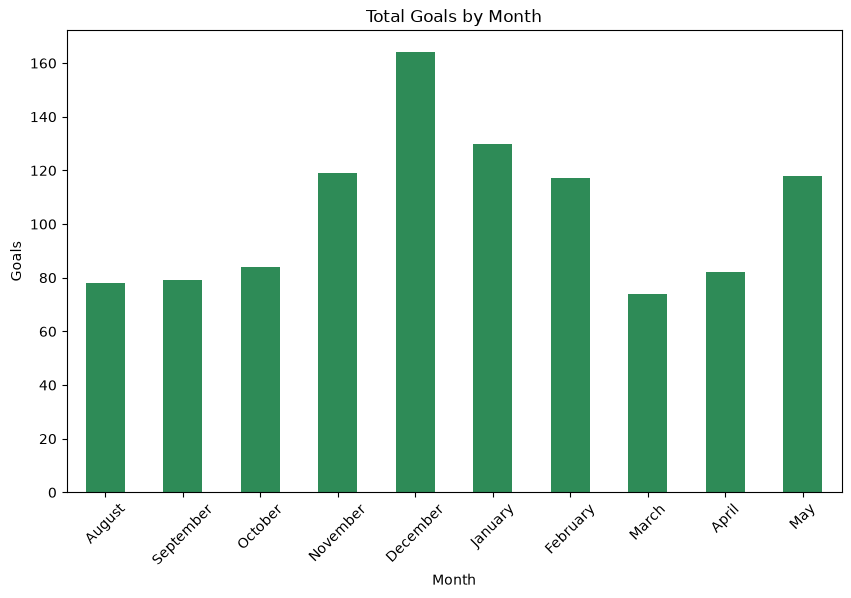

In [12]:
plt.figure(figsize=(10, 6))
goals_by_month.plot(kind="bar", color="seagreen")
plt.title("Total Goals by Month")
plt.ylabel("Goals")
plt.xlabel("Month")
plt.xticks(rotation=45)
plt.show()

In [13]:
matches_by_month = clean_matches.groupby("month")["id"].count().reindex(season_month_order)
goals_per_match = (goals_by_month / matches_by_month).round(2)
goals_per_match

month
August       2.60
September    2.63
October      2.80
November     2.98
December     2.93
January      2.65
February     2.79
March        2.31
April        2.73
May          2.88
dtype: float64

In [14]:
standings_df = pd.read_csv("../data/raw/raw_standings.csv")
standings_df.head()

,position,team,playedGames,form,won,draw,lost,points,goalsFor,goalsAgainst,goalDifference
0,1,"{'id': 57, 'name': 'Arsenal FC', 'shortName': ...",38,"W,W,W,W,W",26,7,5,85,71,27,44
1,2,"{'id': 65, 'name': 'Manchester City FC', 'shor...",38,"L,D,W,W,D",23,9,6,78,77,35,42
2,3,"{'id': 66, 'name': 'Manchester United FC', 'sh...",38,"W,W,D,W,W",20,11,7,71,69,50,19
3,4,"{'id': 58, 'name': 'Aston Villa FC', 'shortNam...",38,"W,W,D,L,L",19,8,11,65,56,49,7
4,5,"{'id': 64, 'name': 'Liverpool FC', 'shortName'...",38,"D,L,D,L,W",17,9,12,60,63,53,10


In [15]:
import ast

standings_df["team"] = standings_df["team"].apply(ast.literal_eval)
standings_df["team_name"] = standings_df["team"].apply(lambda x: x["name"])

standings_df[["position", "team_name", "points"]].head()

,position,team_name,points
0,1,Arsenal FC,85
1,2,Manchester City FC,78
2,3,Manchester United FC,71
3,4,Aston Villa FC,65
4,5,Liverpool FC,60


In [16]:
position_lookup = standings_df.set_index("team_name")["position"]

In [17]:
clean_matches["home_position"] = clean_matches["home_team_name"].map(position_lookup)
clean_matches["away_position"] = clean_matches["away_team_name"].map(position_lookup)

clean_matches[["home_team_name", "home_position", "away_team_name", "away_position", "winner"]].head()

,home_team_name,home_position,away_team_name,away_position,winner
0,Liverpool FC,5,AFC Bournemouth,6,HOME_TEAM
1,Aston Villa FC,4,Newcastle United FC,12,DRAW
2,Brighton & Hove Albion FC,8,Fulham FC,11,DRAW
3,Sunderland AFC,7,West Ham United FC,18,HOME_TEAM
4,Tottenham Hotspur FC,17,Burnley FC,19,HOME_TEAM


In [18]:
def get_upset_magnitude(row):
    if row["winner"] == "HOME_TEAM":
        winner_pos, loser_pos = row["home_position"], row["away_position"]
    elif row["winner"] == "AWAY_TEAM":
        winner_pos, loser_pos = row["away_position"], row["home_position"]
    else:
        return None  # draws aren't upsets in this definition

    # Upset = winner's position number is HIGHER (worse) than loser's
    if winner_pos > loser_pos:
        return winner_pos - loser_pos  # bigger gap = bigger upset
    else:
        return 0  # not an upset, better/equal team won

clean_matches["upset_magnitude"] = clean_matches.apply(get_upset_magnitude, axis=1)

In [19]:
biggest_upsets = clean_matches[clean_matches["upset_magnitude"] > 0].sort_values(
    "upset_magnitude", ascending=False
)

biggest_upsets[[
    "utcDate", "home_team_name", "home_position", "away_team_name", "away_position",
    "home_goals", "away_goals", "winner", "upset_magnitude"
]].head(10)

,utcDate,home_team_name,home_position,away_team_name,away_position,home_goals,away_goals,winner,upset_magnitude
271,2026-02-27 20:00:00+00:00,Wolverhampton Wanderers FC,20,Aston Villa FC,4,2,0,HOME_TEAM,16.0
11,2025-08-23 11:30:00+00:00,Manchester City FC,2,Tottenham Hotspur FC,17,0,2,AWAY_TEAM,15.0
284,2026-03-03 20:15:00+00:00,Wolverhampton Wanderers FC,20,Liverpool FC,5,2,1,HOME_TEAM,15.0
346,2026-05-03 18:00:00+00:00,Aston Villa FC,4,Tottenham Hotspur FC,17,1,2,AWAY_TEAM,13.0
14,2025-08-23 14:00:00+00:00,Burnley FC,19,Sunderland AFC,7,2,0,HOME_TEAM,12.0
114,2025-11-22 15:00:00+00:00,Liverpool FC,5,Nottingham Forest FC,16,0,3,AWAY_TEAM,11.0
29,2025-08-31 18:00:00+00:00,Aston Villa FC,4,Crystal Palace FC,15,0,3,AWAY_TEAM,11.0
318,2026-04-13 19:00:00+00:00,Manchester United FC,3,Leeds United FC,14,1,2,AWAY_TEAM,11.0
220,2026-01-24 12:30:00+00:00,West Ham United FC,18,Sunderland AFC,7,3,1,HOME_TEAM,11.0
119,2025-11-24 20:00:00+00:00,Manchester United FC,3,Everton FC,13,0,1,AWAY_TEAM,10.0
